In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import numpy as np

In [3]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")

# Exploration

In [4]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [6]:
df.columns = df.columns.str.strip() 

In [7]:
df.describe().round(2)

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.00,10000.00,10000.00,10000.00,9123.00,10000.00,9736.00,10000.00
mean,1999.55,3.50,2268.81,6.04,254.45,4286.75,18.89,30.00
std,14.21,0.95,183.45,0.54,22.84,266.21,1.28,2.93
min,1975.00,2.00,1590.00,4.00,171.00,3320.00,14.00,19.80
25%,1987.00,3.00,2150.00,6.00,239.00,4110.00,18.00,28.00
50%,2000.00,4.00,2270.00,6.00,254.00,4280.00,18.90,30.00
75%,2012.00,4.00,2390.00,6.00,270.00,4470.00,19.70,31.90
max,2024.00,5.00,3110.00,8.00,334.00,5460.00,23.80,41.20


In [8]:
df.isna().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [9]:
df.nunique()

model_year              50
origin                   3
fuel_type                3
drivetrain               3
num_doors                4
engine_displacement    127
num_cylinders            5
horsepower             153
vehicle_weight         176
acceleration            93
fuel_efficiency_mpg    188
dtype: int64

In [10]:
df.nunique(dropna=False)

model_year              50
origin                   3
fuel_type                3
drivetrain               3
num_doors                4
engine_displacement    127
num_cylinders            5
horsepower             154
vehicle_weight         176
acceleration            94
fuel_efficiency_mpg    188
dtype: int64

In [11]:
df.iloc[1000:1005]

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
1000,2023,USA,Gasoline,Rear-wheel drive,5,2350,7,273.0,4680,20.7,29.6
1001,2006,USA,Gasoline,All-wheel drive,2,2320,6,265.0,4690,18.8,25.3
1002,1981,Europe,Gasoline,All-wheel drive,4,2410,6,NaN,4730,21.2,26.6
1003,2018,USA,Gasoline,Front-wheel drive,3,2180,6,242.0,4280,18.5,30.3
1004,1987,Asia,Hybrid,Rear-wheel drive,4,1970,5,240.0,3940,18.8,32.7


In [12]:
df.dtypes

model_year               int64
origin                  object
fuel_type               object
drivetrain              object
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [15]:
categorical = df.select_dtypes(include='object').columns
categorical = categorical.tolist()
categorical

['origin', 'fuel_type', 'drivetrain']

In [16]:
df[categorical].nunique()

origin        3
fuel_type     3
drivetrain    3
dtype: int64

In [17]:
for col in categorical:
    print(df[col].value_counts(),'\n')

origin
USA       4202
Asia      2994
Europe    2804
Name: count, dtype: int64 

fuel_type
Gasoline    6913
Diesel      2053
Hybrid      1034
Name: count, dtype: int64 

drivetrain
Front-wheel drive    5519
Rear-wheel drive     2455
All-wheel drive      2026
Name: count, dtype: int64 



In [18]:
numerical = df.select_dtypes(include='number').columns
numerical = numerical.tolist()
numerical

# Notice that fuel_efficiency_mpg is in the numerical list

['model_year',
 'num_doors',
 'engine_displacement',
 'num_cylinders',
 'horsepower',
 'vehicle_weight',
 'acceleration',
 'fuel_efficiency_mpg']

In [19]:
df[numerical] = df[numerical].fillna(0)  

In [20]:
df.isna().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [21]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,0.0,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,0.0,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


<Axes: >

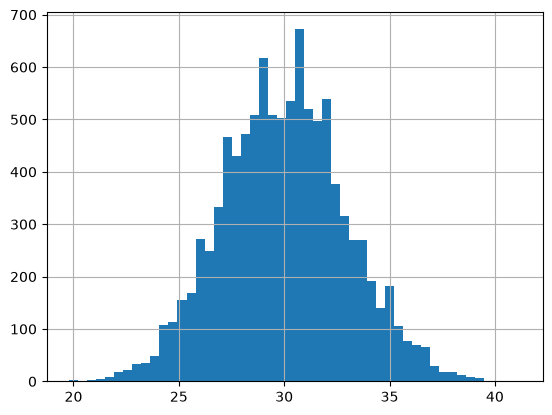

In [22]:
df['fuel_efficiency_mpg'].hist(bins=50)

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [25]:
df_train.corr(numeric_only=True).abs()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
model_year,1.000000,0.016505,0.022272,0.007146,0.318624,0.012217,0.051253,0.502195
num_doors,0.016505,1.000000,0.005212,0.004494,0.005921,0.181713,0.037974,0.023884
engine_displacement,0.022272,0.005212,1.000000,0.660936,0.201966,0.684946,0.014556,0.334480
num_cylinders,0.007146,0.004494,0.660936,1.000000,0.159337,0.522011,0.014418,0.239633
horsepower,0.318624,0.005921,0.201966,0.159337,1.000000,0.159310,0.018022,0.074387
vehicle_weight,0.012217,0.181713,0.684946,0.522011,0.159310,1.000000,0.123143,0.419174
acceleration,0.051253,0.037974,0.014556,0.014418,0.018022,0.123143,1.000000,0.074145
fuel_efficiency_mpg,0.502195,0.023884,0.334480,0.239633,0.074387,0.419174,0.074145,1.000000


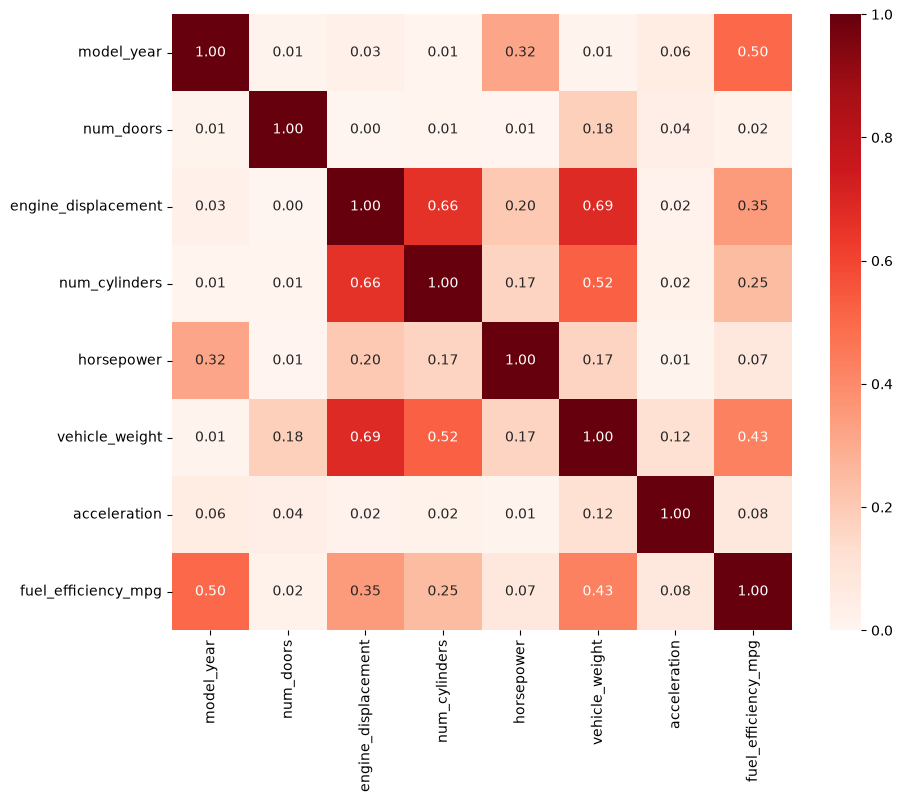

In [26]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True).abs(), annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.show()

In [27]:
for col in categorical:
    print(df_train.groupby(col)['fuel_efficiency_mpg'].agg(['mean', 'count']),'\n')

             mean  count
origin                  
Asia    30.844488   1805
Europe  30.565368   1669
USA     29.050356   2526 

                mean  count
fuel_type                  
Diesel     30.988748   1262
Gasoline   29.223883   4120
Hybrid     33.266828    618 

                        mean  count
drivetrain                         
All-wheel drive    28.903253   1199
Front-wheel drive  30.690003   3371
Rear-wheel drive   29.341329   1430 



In [28]:
df_train.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
4495,2011,USA,Gasoline,Front-wheel drive,4,2370,6,284.0,4280,19.0,30.8
6470,2012,USA,Diesel,All-wheel drive,3,2460,6,288.0,4580,18.8,29.7
2221,1985,Europe,Gasoline,All-wheel drive,3,2070,6,230.0,4150,20.6,27.6
7686,2005,Europe,Diesel,Front-wheel drive,5,2050,5,249.0,4120,0.0,33.7
9419,2004,Asia,Gasoline,Front-wheel drive,2,2160,6,241.0,4020,17.9,29.3


In [29]:
df_train.iloc[1000:1005]

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
3331,1987,Europe,Gasoline,Front-wheel drive,5,2470,6,266.0,3960,18.3,31.6
1081,1976,USA,Gasoline,Front-wheel drive,5,2350,6,272.0,4140,19.9,27.6
2590,1990,Asia,Gasoline,All-wheel drive,4,2490,6,271.0,5010,20.7,27.3
1923,2020,Asia,Diesel,Front-wheel drive,4,2180,6,268.0,4140,19.3,35.1
2035,2016,USA,Gasoline,Front-wheel drive,5,2400,6,273.0,4340,16.6,31.1


In [30]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [31]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [32]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [33]:
df_train.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration
0,2011,USA,Gasoline,Front-wheel drive,4,2370,6,284.0,4280,19.0
1,2012,USA,Diesel,All-wheel drive,3,2460,6,288.0,4580,18.8
2,1985,Europe,Gasoline,All-wheel drive,3,2070,6,230.0,4150,20.6
3,2005,Europe,Diesel,Front-wheel drive,5,2050,5,249.0,4120,0.0
4,2004,Asia,Gasoline,Front-wheel drive,2,2160,6,241.0,4020,17.9


# Question1

In [34]:
from sklearn.feature_extraction import DictVectorizer

In [35]:
train_dicts = df_train.to_dict(orient='records')

In [36]:
dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)

In [37]:
from sklearn.tree import DecisionTreeRegressor

In [38]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [39]:
from sklearn.tree import export_text

In [40]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



## Answer to Question1: model_year

# Question2

In [41]:
from sklearn.ensemble import RandomForestRegressor

In [42]:
dt = RandomForestRegressor(n_estimators=10, n_jobs=-1, random_state=1)

In [43]:
dt.fit(X_train, y_train)

,n_estimators,10
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [44]:
X_val = dv.transform(df_val.to_dict(orient='records'))
y_pred = dt.predict(X_val)

In [45]:
from sklearn.metrics import mean_squared_error

In [46]:
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
rmse

np.float64(1.837054054730018)

## Answer to Question2: 1.837

# Question3

In [47]:
n_estimators = [10, 50, 100, 150]

In [48]:
for n in n_estimators:
    dt = RandomForestRegressor(n_estimators=n, n_jobs=-1, random_state=1)
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    print(f"n_estimators: {n}, RMSE: {rmse:.3f}")

n_estimators: 10, RMSE: 1.837
n_estimators: 50, RMSE: 1.772
n_estimators: 100, RMSE: 1.768
n_estimators: 150, RMSE: 1.769


## Answer to Question3: 100

# Question 4

In [49]:
max_depth = [10, 15, 20, 25]
n_estimators = [10, 50, 100, 150]

In [50]:
for m in max_depth:
    rmse_total = []
    for n in n_estimators:
        dt = RandomForestRegressor(max_depth=m, n_estimators=n, n_jobs=-1, random_state=1)
        dt.fit(X_train, y_train)
        y_pred = dt.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        rmse_total.append(rmse)
    print(f"max_depth: {m}, Mean of RMSE: {np.mean(rmse_total):.3f}")


max_depth: 10, Mean of RMSE: 1.755
max_depth: 15, Mean of RMSE: 1.784
max_depth: 20, Mean of RMSE: 1.788
max_depth: 25, Mean of RMSE: 1.786


## Answer to question 4: 10

# Question 5

In [52]:
dt = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
dt.fit(X_train, y_train)

,n_estimators,10
,criterion,'squared_error'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [54]:
print(dt.feature_importances_)

[0.05520112 0.00768166 0.02014532 0.00578087 0.06100491 0.01703835
 0.16071245 0.01579972 0.07801732 0.29600139 0.00728354 0.01941498
 0.00639091 0.00350451 0.04214438 0.20387857]


In [57]:
index = dv.get_feature_names_out()
importance = pd.Series(
    dt.feature_importances_,
    index=index
)

print(importance.sort_values(ascending=False))

model_year                      0.296001
vehicle_weight                  0.203879
fuel_type=Gasoline              0.160712
horsepower                      0.078017
engine_displacement             0.061005
acceleration                    0.055201
origin=USA                      0.042144
drivetrain=Front-wheel drive    0.020145
num_doors                       0.019415
fuel_type=Diesel                0.017038
fuel_type=Hybrid                0.015800
drivetrain=All-wheel drive      0.007682
num_cylinders                   0.007284
origin=Asia                     0.006391
drivetrain=Rear-wheel drive     0.005781
origin=Europe                   0.003505
dtype: float64


## Answer to Question 5: vehicle_weight

# Question 6

In [58]:
import xgboost as xgb

In [59]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [60]:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

In [61]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [63]:
%%capture output
model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=5)

In [66]:
print(output.stdout)

[0]	train-rmse:2.40653	val-rmse:2.46782
[5]	train-rmse:1.59328	val-rmse:1.76216
[10]	train-rmse:1.47125	val-rmse:1.73205
[15]	train-rmse:1.41908	val-rmse:1.73512
[20]	train-rmse:1.39368	val-rmse:1.73766
[25]	train-rmse:1.35837	val-rmse:1.74359
[30]	train-rmse:1.33243	val-rmse:1.74548
[35]	train-rmse:1.29290	val-rmse:1.75198
[40]	train-rmse:1.25326	val-rmse:1.76296
[45]	train-rmse:1.21527	val-rmse:1.77244
[50]	train-rmse:1.18645	val-rmse:1.77517
[55]	train-rmse:1.14797	val-rmse:1.78668
[60]	train-rmse:1.10265	val-rmse:1.79401
[65]	train-rmse:1.06590	val-rmse:1.80143
[70]	train-rmse:1.04604	val-rmse:1.80444
[75]	train-rmse:1.02727	val-rmse:1.80682
[80]	train-rmse:0.99487	val-rmse:1.81308
[85]	train-rmse:0.96970	val-rmse:1.81600
[90]	train-rmse:0.94986	val-rmse:1.82135
[95]	train-rmse:0.91805	val-rmse:1.82544
[99]	train-rmse:0.90106	val-rmse:1.82646



In [67]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

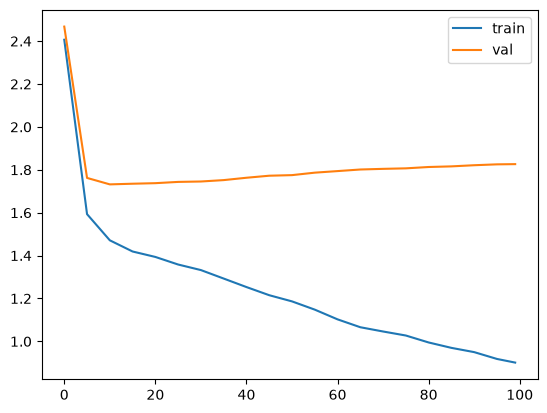

In [68]:
df_score = parse_xgb_output(output)

plt.plot(df_score.num_iter, df_score.train_rmse, label='train')
plt.plot(df_score.num_iter, df_score.val_rmse, label='val')
plt.legend()

In [69]:
y_pred = model.predict(dval)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
rmse

np.float64(1.8264579799904583)

In [70]:
xgb_params_new = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

In [73]:
%%capture output
model_new = xgb.train(xgb_params_new, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=5)

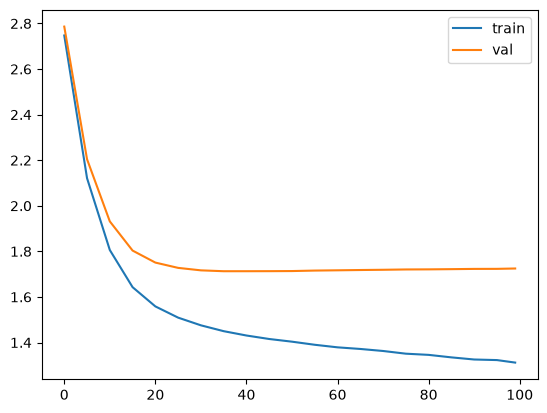

In [74]:
df_score = parse_xgb_output(output)

plt.plot(df_score.num_iter, df_score.train_rmse, label='train')
plt.plot(df_score.num_iter, df_score.val_rmse, label='val')
plt.legend()

In [75]:
y_pred = model_new.predict(dval)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
rmse

np.float64(1.724810059827976)

## Answer to question 6: 0.1 is better